# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

**Konteks.** Tim produk e-commerce ingin mengklasifikasikan sentimen ulasan pelanggan secara otomatis pada halaman produk. Sebelum memilih pendekatan untuk produksi, dilakukan eksperimen awal yang membandingkan dua kandidat.

**Objective.** Membandingkan (1) model klasik Machine Learning (TF-IDF + Scikit-learn) yang dilatih sendiri dan (2) LLM Gemini via API dengan prompting tanpa training, pada test set yang sama, menggunakan Accuracy, Precision, Recall, F1-Score, dan confusion matrix, lalu menyusun rekomendasi technical approach berbasis hasil eksperimen.

**Target/label.** Kolom `sentiment` dengan dua kelas: `positif` dan `negatif` (klasifikasi biner). Input yang digunakan hanya kolom `review_text`.

**Batasan dan asumsi.**
- Dataset resmi dari instruktur digunakan apa adanya dan tidak dimodifikasi.
- Label pada dataset dianggap sebagai ground truth.
- `product_name` tidak dipakai sebagai fitur, karena sentimen ditentukan oleh isi ulasan, bukan nama produk.
- Ulasan berbahasa Indonesia informal dan pendek (6–11 kata).
- Dataset hanya memiliki 40 kalimat unik dari 200 baris, sehingga test set berukuran kecil dan hasil metrik harus diinterpretasikan dengan hati-hati.
- Gemini diakses melalui free tier, sehingga eksperimen tunduk pada rate limit API.

## 2. Import Library & Load Dataset

In [31]:
# 🔧 Sesuaikan nama file jika dataset final berbeda
from pathlib import Path
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay,
)
from dotenv import load_dotenv
from google import genai
from google.genai import types, errors
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
DATA_PATH = Path("..")/ "data"/ "customer_reviews_sentiment.csv"

TEXT_COL = "review_text"
LABEL_COL = "sentiment"

df= pd.read_csv(DATA_PATH)
df.head ()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


### 2.1.a Eksplorasi Data

In [40]:
print("Jumlah baris :", df.shape[0])
print("Jumlah Kolom :", df.shape[1])
print("Nama   Kolom :", df.columns.tolist())
df.info()

Jumlah baris : 200
Jumlah Kolom : 4
Nama   Kolom : ['review_id', 'product_name', 'review_text', 'sentiment']
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   review_id     200 non-null    int64
 1   product_name  200 non-null    str  
 2   review_text   200 non-null    str  
 3   sentiment     200 non-null    str  
dtypes: int64(1), str(3)
memory usage: 6.4 KB


### 2.1.B Missing Values

In [3]:
df.isna().sum()

review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64

### 2.1.c Duplicat

In [4]:
print("Duplikat seluruh kolom    :", df.duplicated().sum())
print("Duplikat tanpa review_id  :", df.drop(columns="review_id").duplicated().sum())
print("Duplikat Review_text      :", df[TEXT_COL].duplicated().sum())
print("Jumlah Review_text unik   :", df[TEXT_COL].nunique())


label_per_text = df.groupby(TEXT_COL)[LABEL_COL].nunique()
print("Teks dengan Label Tidak Konsisten:",(label_per_text >1).sum())

Duplikat seluruh kolom    : 0
Duplikat tanpa review_id  : 31
Duplikat Review_text      : 160
Jumlah Review_text unik   : 40
Teks dengan Label Tidak Konsisten: 0


###  2.1.d: teks yang paling sering berulang

In [5]:
df[TEXT_COL].value_counts().head(10)

review_text
Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.                      12
Produknya rapi dan bersih, tidak ada cacat sama sekali.                     9
Pengiriman lambat sekali, sudah dua minggu belum sampai.                    8
Kualitas produk jelek, baru dipakai sekali sudah rusak.                     8
Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.     8
Packing rapi, produk sesuai deskripsi. Recommended seller!                  7
Produk original dan berfungsi dengan baik, terima kasih!                    7
Sangat puas dengan pembelian ini, akan beli lagi di lain waktu.             7
Respon penjual lambat dan terkesan tidak peduli komplain.                   7
Fast respon, pengiriman cepat, barang aman sampai tujuan.                   7
Name: count, dtype: int64

### 2.1.e distribusi kelas


In [6]:
class_summary = pd.DataFrame({
    "jumlah_baris": df[LABEL_COL].value_counts(),
    "persen": df[LABEL_COL].value_counts(normalize=True).mul(100).round(1),
    "teks_unik": df.groupby(LABEL_COL)[TEXT_COL].nunique(),
})
class_summary

,jumlah_baris,persen,teks_unik
sentiment,,,
negatif,90,45.0,20
positif,110,55.0,20


### 2.1.f: karakteristik teks

In [7]:
text_stats=pd.DataFrame({
    "char_len":df[TEXT_COL].str.len(),
    "word_count":df[TEXT_COL].str.split().str.len(),
    LABEL_COL: df[LABEL_COL],
})
display(text_stats[["char_len","word_count"]].describe().round(2))
text_stats.groupby(LABEL_COL)[["char_len","word_count"]].mean().round(2)

,char_len,word_count
count,200.00,200.00
mean,55.18,7.80
std,5.14,1.11
min,43.00,6.00
25%,53.00,7.00
50%,55.50,8.00
75%,57.00,8.00
max,71.00,11.00


,char_len,word_count
sentiment,,
negatif,54.56,7.64
positif,55.70,7.94


### 2.1.g: distribusi produk

In [8]:
df["product_name"].value_counts() 

product_name
Case HP              22
Rice Cooker          18
Sepatu Sneakers      17
Jaket Hoodie         16
Tas Ransel           16
Headset Bluetooth    14
Kursi Lipat          14
Charger Cepat        14
Botol Minum          13
Kaos Polos           12
Lampu LED            11
Kemeja Flanel        10
Sandal Jepit         10
Powerbank             7
Blender Mini          6
Name: count, dtype: int64

### 2.2 Ringkasan Eksplorasi Data

- Dataset berisi **200 ulasan** dengan 4 kolom: `review_id`, `product_name`, `review_text`, `sentiment`.
- **Tidak ada missing value**, dan setiap teks memiliki label yang konsisten.
- Distribusi kelas **cukup seimbang**: positif 110 (55%) dan negatif 90 (45%). Accuracy masih bermakna, tetapi tetap dilengkapi Precision, Recall, dan F1.
- Ulasan **sangat pendek** (rata-rata 7,8 kata) dan panjangnya hampir sama antar kelas, sehingga panjang teks tidak bisa dipakai untuk membedakan sentimen.
- **Temuan kritis:** hanya **40 kalimat unik** (20 positif, 20 negatif). Setiap kalimat diulang rata-rata 5 kali (maksimum 12) dengan `product_name` berbeda. Split acak biasa akan menempatkan kalimat yang sama di train dan test, sehingga terjadi **data leakage** dan skor model klasik menggelembung.
- Beberapa ulasan positif memakai kata yang biasanya negatif, misalnya "**tidak** mengecewakan" dan "**tidak** ada **cacat**". Ini menjadi tantangan untuk model berbasis kata seperti TF-IDF.

**Implikasi untuk eksperimen:** pembagian data dilakukan berbasis grup `review_text` agar kalimat di test set tidak pernah terlihat saat training (skenario utama). Split acak biasa tetap dijalankan sebagai pembanding untuk mengukur efek leakage.

## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

In [9]:
# 🔧 Sesuaikan nama kolom jika dataset final menggunakan nama kolom berbeda
RANDOM_STATE=42
TEST_SIZE=0.2

RESULTS_DIR=Path("..")/ "results"
RESULTS_DIR.mkdir(exist_ok=True)

In [10]:
X=df[TEXT_COL]
y=df[LABEL_COL]
groups=df[TEXT_COL]

In [11]:
sgkf= StratifiedGroupKFold(
    n_splits=int(1/TEST_SIZE),
    shuffle=True,
    random_state=RANDOM_STATE,
)
train_idx, test_idx =next (sgkf.split(X,y,groups=groups))
X_train, X_test=X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test=y.iloc[train_idx], y.iloc[test_idx]


In [12]:
X_train_rand, X_test_rand, y_train_rand, y_test_rand =train_test_split(
    X,y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

In [13]:
def split_summary(y_tr, y_te):
    """Tabel jumlah dan persentase kelas di train dan test."""
    return pd.DataFrame({
        "train_n": y_tr.value_counts(),
        "train_%": y_tr.value_counts(normalize=True).mul(100).round(1),
        "test_n": y_te.value_counts(),
        "test_%": y_te.value_counts(normalize=True).mul(100).round(1),
    })

print("Skenario utama — group split")
display(split_summary(y_train, y_test))

print("Skenario pembanding — random split")
display(split_summary(y_train_rand, y_test_rand))

Skenario utama — group split


,train_n,train_%,test_n,test_%
sentiment,,,,
positif,88,55.0,22,55.0
negatif,72,45.0,18,45.0


Skenario pembanding — random split


,train_n,train_%,test_n,test_%
sentiment,,,,
positif,88,55.0,22,55.0
negatif,72,45.0,18,45.0


In [14]:
def leakage_report(X_tr, X_te):
    """Hitung berapa baris test yang kalimatnya juga muncul di train."""
    seen_in_train = X_te.isin(set(X_tr))
    return {
        "baris_test": len(X_te),
        "teks_unik_test": X_te.nunique(),
        "baris_test_ada_di_train": int(seen_in_train.sum()),
        "persen_bocor": round(seen_in_train.mean() * 100, 1),
    }

leakage_table = pd.DataFrame({
    "group_split": leakage_report(X_train, X_test),
    "random_split": leakage_report(X_train_rand, X_test_rand),
})
display(leakage_table)

# Pengaman: notebook berhenti di sini jika skenario utama ternyata bocor
assert leakage_table.loc["baris_test_ada_di_train", "group_split"] == 0, "Group split bocor!"

,group_split,random_split
baris_test,40.0,40.0
teks_unik_test,8.0,26.0
baris_test_ada_di_train,0.0,39.0
persen_bocor,0.0,97.5


In [15]:
# Simpan review_id (bukan posisi baris) karena ID melekat pada data asli
test_ids_group = df.loc[X_test.index, "review_id"]
test_ids_random = df.loc[X_test_rand.index, "review_id"]

test_ids_group.to_csv(RESULTS_DIR / "test_ids_group_split.csv", index=False)
test_ids_random.to_csv(RESULTS_DIR / "test_ids_random_split.csv", index=False)

print("Tersimpan:", len(test_ids_group), "ID (group) dan", len(test_ids_random), "ID (random)")

Tersimpan: 40 ID (group) dan 40 ID (random)


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [16]:
def build_classic_model():
    return Pipeline([
        ("tfidf",TfidfVectorizer(
            lowercase=True,
            ngram_range=(1,2),
        )),
        ("clf",LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ])
build_classic_model()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None


### 4.2 Training Model

In [17]:
def train_classic(X_tr, y_tr):
    model = build_classic_model()
    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_seconds = time.perf_counter() - start
    return model, train_seconds

model_group, train_s_group = train_classic(X_train, y_train)
model_rand, train_s_rand = train_classic(X_train_rand, y_train_rand)

print("Ukuran kosakata (group) :", len(model_group.named_steps["tfidf"].vocabulary_))
print("Ukuran kosakata (random):", len(model_rand.named_steps["tfidf"].vocabulary_))
print("Urutan kelas model      :", model_group.classes_)

Ukuran kosakata (group) : 333
Ukuran kosakata (random): 384
Urutan kelas model      : ['negatif' 'positif']


### 4.3 Prediksi pada Test Set

In [18]:
def predict_classic(model, X_te):
    """Memprediksi test set dan mengukur waktu inference (detik)."""
    start = time.perf_counter()
    y_pred = model.predict(X_te)
    infer_seconds = time.perf_counter() - start
    return pd.Series(y_pred, index=X_te.index, name="y_pred"), infer_seconds

y_pred_classic, infer_s_group = predict_classic(model_group, X_test)
y_pred_classic_rand, infer_s_rand = predict_classic(model_rand, X_test_rand)

In [19]:
def save_predictions(X_te, y_te, y_pred, filename):
    output = pd.DataFrame({
        "review_id": df.loc[X_te.index, "review_id"],
        "review_text": X_te,
        "y_true": y_te,
        "y_pred": y_pred,
    })
    output.to_csv(RESULTS_DIR / filename, index=False)
    return output

pred_classic_group = save_predictions(X_test, y_test, y_pred_classic, "predictions_classic_group.csv")
pred_classic_rand = save_predictions(X_test_rand, y_test_rand, y_pred_classic_rand, "predictions_classic_random.csv")

print("Distribusi prediksi (group) :", y_pred_classic.value_counts().to_dict())
print("Distribusi prediksi (random):", y_pred_classic_rand.value_counts().to_dict())
pred_classic_group.head()

Distribusi prediksi (group) : {'negatif': 21, 'positif': 19}
Distribusi prediksi (random): {'positif': 22, 'negatif': 18}


,review_id,review_text,y_true,y_pred
6,7,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif
7,8,"Belanja disini selalu puas, kualitas terjaga.",positif,positif
13,14,"Barang yang datang tidak sesuai dengan foto, k...",negatif,negatif
14,15,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif
21,22,"Sudah langganan di toko ini, kualitas selalu k...",positif,positif


In [20]:
classic_timing = pd.DataFrame({
    "group_split": {"train_detik": train_s_group, "inference_detik": infer_s_group},
    "random_split": {"train_detik": train_s_rand, "inference_detik": infer_s_rand},
}).round(4)
classic_timing

,group_split,random_split
train_detik,0.0069,0.0074
inference_detik,0.0012,0.0012


In [21]:

feature_names = model_group.named_steps["tfidf"].get_feature_names_out()
coefficients = model_group.named_steps["clf"].coef_[0]

word_weights = pd.Series(coefficients, index=feature_names).sort_values()
print("10 fitur paling NEGATIF:\n", word_weights.head(10).round(3), "\n")
print("10 fitur paling POSITIF:\n", word_weights.tail(10).round(3))

10 fitur paling NEGATIF:
 lambat         -0.864
sekali         -0.826
sekali sudah   -0.698
sudah          -0.698
lambat dan     -0.653
seperti        -0.625
jauh           -0.617
jauh dari      -0.617
berbeda        -0.605
warna          -0.605
dtype: float64 

10 fitur paling POSITIF:
 nyaman                0.577
nyaman dipakai        0.577
tidak mengecewakan    0.577
dipakai ukuran        0.577
pas tidak             0.577
pas                   0.577
banget                0.692
dengan                0.755
sesuai                0.771
cepat                 1.127
dtype: float64


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [25]:

load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")
if not api_key:
    raise SystemExit("GEMINI_API_KEY tidak ditemukan. Cek file .env di root project.")
print("API key terbaca: ****" + api_key[-4:])

client = genai.Client(api_key=api_key)

# Konfigurasi eksperimen — dicatat sebagai parameter yang dilaporkan
MODEL_NAME = "gemini-3.5-flash-lite"  
TEMPERATURE = 0.0                      
REQUEST_DELAY_S = 6                    
MAX_RETRIES = 4                        

API key terbaca: ****v7Kg


### 5.2 Merancang Prompt



In [26]:
SYSTEM_PROMPT = """You are a sentiment classification system for Indonesian e-commerce customer reviews.

Task: classify the OVERALL sentiment of the review written by the customer.

Label definitions:
- POSITIVE: the customer is satisfied overall, e.g. praises the product quality, the seller, the packaging, the delivery speed, or says the product matches the description or expectations.
- NEGATIVE: the customer is dissatisfied overall, e.g. complains about defects, damage, mismatch with the description or photos, slow delivery, unresponsive service, fake products, or wasted money.

Rules:
1. Judge the meaning of the whole review, not individual words. Negation can reverse meaning (for example, "not bad" expresses a positive opinion).
2. If the review is mixed or ambiguous, choose the label that best reflects the customer's overall satisfaction.
3. Respond with exactly one word: POSITIVE or NEGATIVE. Do not add explanations, punctuation, or any other text."""

LABEL_MAP = {"POSITIVE": "positif", "NEGATIVE": "negatif"}
RETRYABLE_CODES = {429, 500, 503}   # rate limit & gangguan server: layak dicoba ulang


def parse_label(raw_text):
    """Ubah jawaban mentah Gemini menjadi label dataset; None jika tidak valid."""
    if not raw_text:
        return None
    cleaned = raw_text.strip().upper().strip(".!\"'` ")
    return LABEL_MAP.get(cleaned)


def classify_with_gemini(review_text):
    """Klasifikasi satu ulasan dengan retry; tidak pernah menebak label saat gagal."""
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            start = time.perf_counter()
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=f'Review: """{review_text}"""',
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM_PROMPT,
                    temperature=TEMPERATURE,
                ),
            )
            latency_s = time.perf_counter() - start

            usage = response.usage_metadata
            label = parse_label(response.text)
            return {
                "raw_response": response.text,
                "label": label,
                "status": "ok" if label else "invalid",
                "latency_s": latency_s,
                "input_tokens": getattr(usage, "prompt_token_count", None),
                "output_tokens": getattr(usage, "candidates_token_count", None),
                "thinking_tokens": getattr(usage, "thoughts_token_count", None),
                "attempts": attempt,
            }

        except errors.APIError as error:
            if error.code in RETRYABLE_CODES and attempt < MAX_RETRIES:
                wait_s = 5 * 2 ** attempt          # 10, 20, 40 detik
                print(f"  Error {error.code}, coba lagi dalam {wait_s} detik...")
                time.sleep(wait_s)
                continue
            return {
                "raw_response": str(error)[:200],
                "label": None,
                "status": f"error_{error.code}",
                "latency_s": None,
                "input_tokens": None,
                "output_tokens": None,
                "thinking_tokens": None,
                "attempts": attempt,
            }

In [27]:
for sample_text in X_train.drop_duplicates().head(2):
    result = classify_with_gemini(sample_text)
    print(sample_text)
    print("  ->", result["status"], "|", repr(result["raw_response"]), "|", result["label"],
          "| tokens in/out/thinking:", result["input_tokens"], result["output_tokens"], result["thinking_tokens"])
    time.sleep(REQUEST_DELAY_S)

Pelayanan lambat dan tidak responsif saat dikomplain.
  -> ok | 'NEGATIVE' | negatif | tokens in/out/thinking: 220 1 None
Puas banget belanja disini, proses cepat dan barang aman.
  -> ok | 'POSITIVE' | positif | tokens in/out/thinking: 219 1 None


### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).

In [28]:
CACHE_PATH = RESULTS_DIR / "gemini_responses.csv"

# Semua kalimat unik dari kedua test set
texts_to_classify = pd.concat([X_test, X_test_rand]).drop_duplicates().tolist()

if CACHE_PATH.exists():
    cache = pd.read_csv(CACHE_PATH)
else:
    cache = pd.DataFrame(columns=["review_text", "label", "status"])

done_texts = set(cache.loc[cache["status"] == "ok", "review_text"])
pending_texts = [text for text in texts_to_classify if text not in done_texts]
print(f"Kalimat unik: {len(texts_to_classify)} | sudah di cache: {len(done_texts)} | akan dipanggil: {len(pending_texts)}")

new_records = []
for i, text in enumerate(pending_texts, start=1):
    result = classify_with_gemini(text)
    result["review_text"] = text
    result["model"] = MODEL_NAME
    result["temperature"] = TEMPERATURE
    new_records.append(result)
    print(f"[{i}/{len(pending_texts)}] {result['status']:<10} {result['label']}  | {text[:50]}")
    time.sleep(REQUEST_DELAY_S)

if new_records:
    cache = pd.concat(
        [cache[~cache["review_text"].isin(pending_texts)], pd.DataFrame(new_records)],
        ignore_index=True,
    )
    cache.to_csv(CACHE_PATH, index=False)

cache["status"].value_counts()

Kalimat unik: 28 | sudah di cache: 0 | akan dipanggil: 28
[1/28] ok         negatif  | Sudah bayar mahal tapi kualitas jauh dari ekspekta
[2/28] ok         positif  | Belanja disini selalu puas, kualitas terjaga.
[3/28] ok         negatif  | Barang yang datang tidak sesuai dengan foto, kecew
[4/28] ok         negatif  | Barang tidak berfungsi sama sekali begitu diterima
[5/28] ok         positif  | Sudah langganan di toko ini, kualitas selalu konsi
[6/28] ok         negatif  | Bahan murahan, tidak sesuai dengan harga yang diba
[7/28] ok         positif  | Produknya rapi dan bersih, tidak ada cacat sama se
[8/28] ok         positif  | Barang datang lebih cepat dari perkiraan, kualitas
[9/28] ok         positif  | Suka banget sama warnanya, sesuai ekspektasi.
[10/28] ok         positif  | Kualitas produk sangat memuaskan, akan order lagi.
[11/28] ok         negatif  | Ukuran tidak sesuai, terlalu kecil dari yang dipes
[12/28] ok         positif  | Fast respon, pengiriman cepat, barang am

status
ok    28
Name: count, dtype: int64

In [29]:
label_lookup = cache.set_index("review_text")["label"]

# Kalimat yang gagal tetap ditandai GAGAL, tidak diubah menjadi positif/negatif
y_pred_llm = X_test.map(label_lookup).fillna("GAGAL").rename("y_pred")
y_pred_llm_rand = X_test_rand.map(label_lookup).fillna("GAGAL").rename("y_pred")

pred_llm_group = save_predictions(X_test, y_test, y_pred_llm, "predictions_gemini_group.csv")
pred_llm_rand = save_predictions(X_test_rand, y_test_rand, y_pred_llm_rand, "predictions_gemini_random.csv")

print("Distribusi prediksi (group) :", y_pred_llm.value_counts().to_dict())
print("Distribusi prediksi (random):", y_pred_llm_rand.value_counts().to_dict())

Distribusi prediksi (group) : {'positif': 22, 'negatif': 18}
Distribusi prediksi (random): {'positif': 22, 'negatif': 18}


In [30]:
ok_calls = cache[cache["status"] == "ok"]

gemini_usage = pd.Series({
    "model": MODEL_NAME,
    "temperature": TEMPERATURE,
    "jumlah_panggilan_ok": len(ok_calls),
    "total_latency_detik": round(ok_calls["latency_s"].sum(), 2),
    "rata2_latency_per_ulasan_detik": round(ok_calls["latency_s"].mean(), 3),
    "total_input_tokens": ok_calls["input_tokens"].sum(),
    "total_output_tokens": ok_calls["output_tokens"].sum(),
    "total_thinking_tokens": ok_calls["thinking_tokens"].fillna(0).sum(),
})
gemini_usage

model                             gemini-3.5-flash-lite
temperature                                         0.0
jumlah_panggilan_ok                                  28
total_latency_detik                               20.36
rata2_latency_per_ulasan_detik                    0.727
total_input_tokens                               6151.0
total_output_tokens                                28.0
total_thinking_tokens                                 0
dtype: object

## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

In [32]:
LABELS = ["negatif", "positif"]  

DOC_DIR = Path("..") / "documentation"
DOC_DIR.mkdir(exist_ok=True)

experiments = [
    ("group_split", "Classical ML", y_test, y_pred_classic),
    ("group_split", "Gemini", y_test, y_pred_llm),
    ("random_split", "Classical ML", y_test_rand, y_pred_classic_rand),
    ("random_split", "Gemini", y_test_rand, y_pred_llm_rand),
]


def keep_valid(y_true, y_pred):
    is_valid = y_pred.isin(LABELS)
    return y_true[is_valid], y_pred[is_valid], int((~is_valid).sum())


def evaluate(scenario, model_name, y_true, y_pred):
    y_true_valid, y_pred_valid, n_failed = keep_valid(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true_valid, y_pred_valid, labels=LABELS, average="macro", zero_division=0
    )
    return {
        "skenario": scenario,
        "model": model_name,
        "n_test": len(y_true),
        "n_dievaluasi": len(y_true_valid),
        "n_gagal": n_failed,
        "accuracy": accuracy_score(y_true_valid, y_pred_valid),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }


def print_report(scenario, model_name, y_true, y_pred):
    y_true_valid, y_pred_valid, n_failed = keep_valid(y_true, y_pred)
    print(f"=== {model_name} | {scenario} | dievaluasi {len(y_true_valid)} baris, gagal {n_failed} ===")
    print(classification_report(y_true_valid, y_pred_valid, labels=LABELS, digits=4, zero_division=0))

In [33]:
for scenario, model_name, y_true, y_pred in experiments:
    if model_name == "Classical ML":
        print_report(scenario, model_name, y_true, y_pred)

=== Classical ML | group_split | dievaluasi 40 baris, gagal 0 ===
              precision    recall  f1-score   support

     negatif     0.5714    0.6667    0.6154        18
     positif     0.6842    0.5909    0.6341        22

    accuracy                         0.6250        40
   macro avg     0.6278    0.6288    0.6248        40
weighted avg     0.6335    0.6250    0.6257        40

=== Classical ML | random_split | dievaluasi 40 baris, gagal 0 ===
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



### 6.2 Evaluasi LLM API

In [34]:
for scenario, model_name, y_true, y_pred in experiments:
    if model_name == "Gemini":
        print_report(scenario, model_name, y_true, y_pred)

=== Gemini | group_split | dievaluasi 40 baris, gagal 0 ===
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

=== Gemini | random_split | dievaluasi 40 baris, gagal 0 ===
              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40



### 6.3 Tabel Perbandingan Ringkasan



### CONFUSION MATRIX

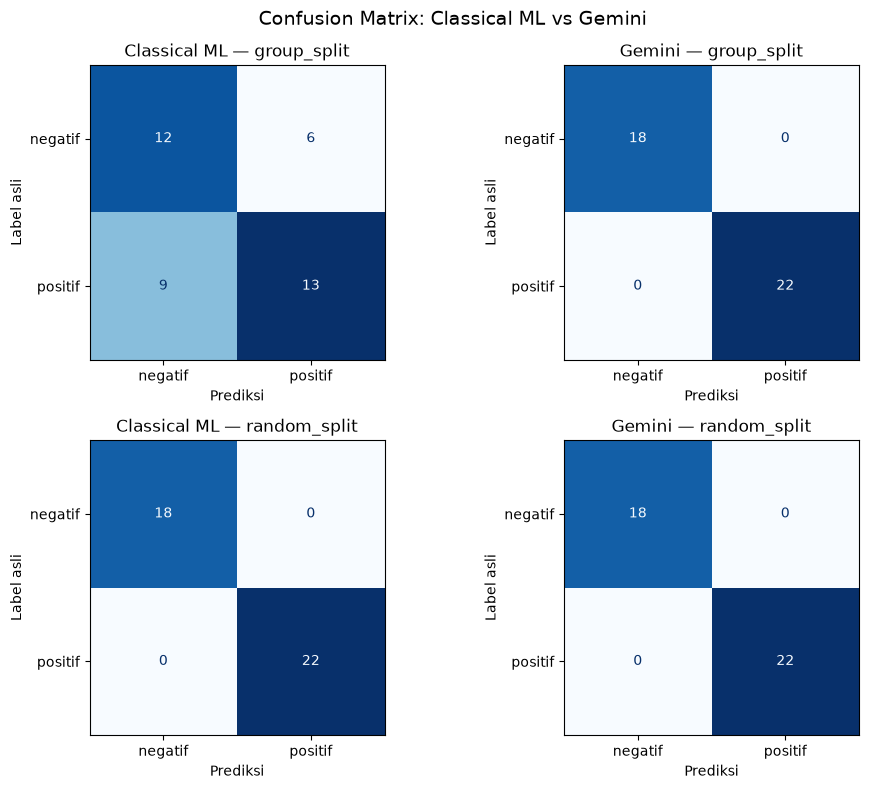

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (scenario, model_name, y_true, y_pred) in zip(axes.ravel(), experiments):
    y_true_valid, y_pred_valid, _ = keep_valid(y_true, y_pred)
    ConfusionMatrixDisplay.from_predictions(
        y_true_valid, y_pred_valid, labels=LABELS, ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f"{model_name} — {scenario}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label asli")

fig.suptitle("Confusion Matrix: Classical ML vs Gemini", fontsize=14)
fig.tight_layout()
fig.savefig(DOC_DIR / "model_comparison_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### TABEL PERBANDINGAN

In [36]:
comparison_table = pd.DataFrame([evaluate(*exp) for exp in experiments])
comparison_table.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)
comparison_table.round(4)

,skenario,model,n_test,n_dievaluasi,n_gagal,accuracy,precision_macro,recall_macro,f1_macro
0,group_split,Classical ML,40,40,0,0.625,0.6278,0.6288,0.6248
1,group_split,Gemini,40,40,0,1.000,1.0000,1.0000,1.0000
2,random_split,Classical ML,40,40,0,1.000,1.0000,1.0000,1.0000
3,random_split,Gemini,40,40,0,1.000,1.0000,1.0000,1.0000


### ACCURACY PER KALIMAT UNIK

In [37]:
def sentence_level(scenario, model_name, X_te, y_te, y_pred):
    """Akurasi jika setiap kalimat unik dihitung satu kali (tanpa efek pengulangan)."""
    unique_rows = pd.DataFrame({"text": X_te, "y_true": y_te, "y_pred": y_pred}).drop_duplicates("text")
    return {
        "skenario": scenario,
        "model": model_name,
        "kalimat_unik": len(unique_rows),
        "kalimat_benar": int((unique_rows["y_true"] == unique_rows["y_pred"]).sum()),
    }

sentence_table = pd.DataFrame([
    sentence_level("group_split", "Classical ML", X_test, y_test, y_pred_classic),
    sentence_level("group_split", "Gemini", X_test, y_test, y_pred_llm),
    sentence_level("random_split", "Classical ML", X_test_rand, y_test_rand, y_pred_classic_rand),
    sentence_level("random_split", "Gemini", X_test_rand, y_test_rand, y_pred_llm_rand),
])
sentence_table["akurasi_kalimat"] = (sentence_table["kalimat_benar"] / sentence_table["kalimat_unik"]).round(4)
sentence_table

,skenario,model,kalimat_unik,kalimat_benar,akurasi_kalimat
0,group_split,Classical ML,8,6,0.75
1,group_split,Gemini,8,8,1.00
2,random_split,Classical ML,26,26,1.00
3,random_split,Gemini,26,26,1.00


### ANALISA KESALAHAN

In [38]:
def wrong_predictions(model_name, X_te, y_te, y_pred):
    """Daftar kalimat yang salah diprediksi beserta jumlah baris yang terdampak."""
    rows = pd.DataFrame({"review_text": X_te, "y_true": y_te, "y_pred": y_pred})
    rows = rows[rows["y_true"] != rows["y_pred"]]
    summary = rows.groupby(["review_text", "y_true", "y_pred"]).size().rename("jumlah_baris").reset_index()
    return summary.assign(model=model_name)

error_analysis = pd.concat([
    wrong_predictions("Classical ML", X_test, y_test, y_pred_classic),
    wrong_predictions("Gemini", X_test, y_test, y_pred_llm),
], ignore_index=True)

print("Kesalahan prediksi pada skenario utama (group split):")
error_analysis

Kesalahan prediksi pada skenario utama (group split):


,review_text,y_true,y_pred,jumlah_baris,model
0,"Bahan murahan, tidak sesuai dengan harga yang ...",negatif,positif,6,Classical ML
1,"Produknya rapi dan bersih, tidak ada cacat sam...",positif,negatif,9,Classical ML


## 7. Analisis Trade-off dan Limitation

### 7.1 Ringkasan perbandingan

| Aspek | Classical ML (TF-IDF + Logistic Regression) | Gemini AI API (gemini-3.5-flash-lite, zero-shot) |
|---|---|---|
| **Performa (group split, skenario utama)** | Accuracy 62,5%, F1-macro 0,62; benar 6 dari 8 kalimat unik | Accuracy 100%, F1-macro 1,00; benar 8 dari 8 kalimat unik |
| **Performa (random split, ada leakage)** | 100% — skor menggelembung karena 97,5% kalimat test sudah dilihat saat training | 100% — tidak terpengaruh leakage karena tidak ada training |
| **Implementasi** | Perlu data berlabel, preprocessing, training, dan pemilihan fitur (mis. bigram untuk negasi) | Tanpa training; effort ada pada desain prompt, parsing output, retry, rate limit, dan caching |
| **Kecepatan** | Training dan inference dalam orde milidetik, lokal | ±0,73 detik per ulasan (termasuk latensi jaringan); ±24.000x lebih lambat (orde puluhan ribu kali)x lebih lambat |
| **Biaya** | Komputasi lokal; biaya API 0 | Gratis di free tier (dengan rate limit); paid tier ±USD 0,0000684 per ulasan ≈ USD 68 per 1 juta ulasan (±USD 34 dengan Batch API) |
| **Fleksibilitas** | Hanya mengenali pola kata dari training; perlu retrain untuk domain atau label baru | Dapat menangani kalimat baru dan negasi tanpa contoh; label/aturan diubah cukup lewat prompt |
| **Maintenance** | Perlu retrain berkala dan pengumpulan data berlabel baru | Bergantung pada layanan eksternal: model bisa deprecated (seri 2.5 sudah dijadwalkan pensiun), harga dan rate limit bisa berubah |
| **Limitation** | Gagal pada negasi; belajar korelasi kata yang keliru dari data template | Biaya dan latensi per request; data dikirim ke pihak ketiga; output perlu divalidasi |

### 7.2 Performa
Pada skenario yang adil (group split), **Gemini unggul di semua metrik**: Accuracy, Precision, Recall, dan F1 semuanya 1,00, dibanding 0,62–0,63 pada model klasik. Keunggulan ini hanya terlihat karena test set bebas leakage. Pada random split (seperti starter notebook), kedua model sama-sama 100%, sehingga split acak akan menghasilkan kesimpulan yang keliru bahwa kedua pendekatan setara.

### 7.3 Limitation Classical ML (temuan eksperimen)
- **Negasi.** Seluruh kesalahan (15 baris dari 2 kalimat) melibatkan negasi: "tidak ada cacat sama sekali" diprediksi negatif (9 baris), dan "tidak sesuai dengan harga" diprediksi positif (6 baris).
- **Korelasi kata yang menyesatkan.** Bobot model menunjukkan kata netral menjadi fitur terkuat: `sesuai` (+0,77), `dengan` (+0,76), dan `sekali` (−0,83). Model mempelajari pola template dataset, bukan makna sentimen.
- **Ketergantungan pada data training.** Dengan hanya 32 kalimat unik di training, kosakata model terbatas, dan kata yang belum pernah dilihat tidak dikenali.

### 7.4 Limitation Gemini (temuan eksperimen)
- **Latensi dan skalabilitas.** ±0,73 detik per ulasan dan tunduk pada rate limit per project, sehingga volume besar memerlukan paralelisasi, batching, atau paid tier.
- **Biaya variabel.** Biaya bertambah linear dengan jumlah ulasan. Sekitar 99% token input berasal dari system prompt (±220 token per panggilan vs ulasan ±15 token), sehingga panjang prompt adalah pendorong biaya utama.
- **Ketergantungan layanan eksternal.** Ketersediaan model, harga, dan kuota ditentukan Google. Kode harus siap untuk error 429/5xx (sudah ditangani dengan retry dan cache).
- **Privasi data.** Pada free tier, data request dapat digunakan Google untuk meningkatkan produk. Untuk ulasan yang memuat data pribadi pelanggan, perlu paid tier dan kebijakan data yang sesuai.
- **Output non-deterministik secara prinsip.** Walaupun temperature 0 dan semua 28 respons valid, output LLM tetap harus divalidasi. Parser dan status `invalid` disiapkan untuk itu.

### 7.5 Keterbatasan eksperimen (berlaku untuk keduanya)
- Dataset hanya memiliki **40 kalimat unik** berbentuk template. Test set utama hanya **8 kalimat unik**, sehingga satu kalimat salah dapat menggeser accuracy hingga 22,5 poin.
- Ulasan sangat pendek dan sentimennya jelas. Hasil 100% Gemini belum membuktikan performa yang sama pada ulasan nyata yang lebih panjang, ambigu, campuran, atau sarkastik.
- Model klasik sengaja tidak di-tuning (baseline), sedangkan Gemini memakai satu desain prompt zero-shot.

### efesiensi dan estimasi biaya

In [39]:

PRICE_INPUT_PER_1M_USD = 0.30
PRICE_OUTPUT_PER_1M_USD = 2.50
SCALE_REVIEWS = 1_000_000   

avg_input_tokens = ok_calls["input_tokens"].mean()
avg_output_tokens = (ok_calls["output_tokens"] + ok_calls["thinking_tokens"].fillna(0)).mean()
gemini_cost_per_review = (
    avg_input_tokens * PRICE_INPUT_PER_1M_USD + avg_output_tokens * PRICE_OUTPUT_PER_1M_USD
) / 1_000_000

classic_infer_per_review = infer_s_group / len(X_test)
gemini_infer_per_review = ok_calls["latency_s"].mean()

efficiency_table = pd.DataFrame({
    "Classical ML": {
        "waktu_training_detik": train_s_group,
        "inference_per_ulasan_detik": classic_infer_per_review,
        "rata2_token_input_per_ulasan": 0,
        "biaya_api_per_ulasan_usd": 0.0,
        f"biaya_api_{SCALE_REVIEWS:,}_ulasan_usd": 0.0,
        f"waktu_inference_{SCALE_REVIEWS:,}_ulasan_jam (berurutan)": classic_infer_per_review * SCALE_REVIEWS / 3600,
    },
    "Gemini": {
        "waktu_training_detik": 0.0,
        "inference_per_ulasan_detik": gemini_infer_per_review,
        "rata2_token_input_per_ulasan": avg_input_tokens,
        "biaya_api_per_ulasan_usd": gemini_cost_per_review,
        f"biaya_api_{SCALE_REVIEWS:,}_ulasan_usd": gemini_cost_per_review * SCALE_REVIEWS,
        f"waktu_inference_{SCALE_REVIEWS:,}_ulasan_jam (berurutan)": gemini_infer_per_review * SCALE_REVIEWS / 3600,
    },
})

print(f"Gemini {gemini_infer_per_review / classic_infer_per_review:,.0f}x lebih lambat per ulasan dibanding Classical ML")
efficiency_table

Gemini 24,107x lebih lambat per ulasan dibanding Classical ML


,Classical ML,Gemini
waktu_training_detik,0.006911,0.000000
inference_per_ulasan_detik,0.000030,0.727297
rata2_token_input_per_ulasan,0.000000,219.678571
biaya_api_per_ulasan_usd,0.000000,0.000068
"biaya_api_1,000,000_ulasan_usd",0.000000,68.403571
"waktu_inference_1,000,000_ulasan_jam (berurutan)",0.008381,202.026908


## 8. Rekomendasi Technical Approach

### Jawaban atas pertanyaan kunci

1. **Model mana yang lebih unggul berdasarkan metrik?**
   Gemini. Pada skenario bebas leakage, Gemini mencapai Accuracy, Precision, Recall, dan F1 sebesar 1,00 dibanding 0,62–0,63 pada Classical ML. Keunggulan utamanya ada pada pemahaman negasi, sumber dari seluruh kesalahan model klasik.

2. **Model mana yang lebih efisien?**
   Classical ML. Inference berjalan lokal dalam orde milidetik, ±24.000xlebih cepat per ulasan dibanding Gemini (±0,73 detik), tanpa ketergantungan jaringan maupun rate limit.

3. **Model mana yang lebih ekonomis untuk jangka panjang?**
   Bergantung pada volume. Biaya marginal Classical ML mendekati nol, sedangkan Gemini bertambah linear (±USD 68 per 1 juta ulasan di paid tier, ±USD 34 dengan Batch API, berdasarkan token aktual eksperimen ini). Namun model klasik memiliki biaya tersembunyi: pengumpulan data berlabel dan retrain berkala. Untuk volume ulasan e-commerce skala kecil–menengah, biaya Gemini relatif kecil dibanding biaya membangun dataset berlabel berkualitas.

4. **Apa risiko dan keterbatasan masing-masing?**
   - *Classical ML:* salah pada negasi dan kalimat baru; performanya sangat bergantung pada kualitas dan keragaman data training; skor bisa terlihat menyesatkan jika evaluasi mengandung leakage.
   - *Gemini:* biaya dan latensi per request, ketergantungan pada layanan eksternal (deprecation model, perubahan harga/kuota), serta isu privasi data (free tier).

5. **Model mana yang sebaiknya dikembangkan lebih lanjut?**
   **Gemini direkomendasikan sebagai pendekatan utama untuk dikembangkan lebih lanjut**, dengan Classical ML dipertahankan sebagai baseline.

### Alasan
- Pada satu-satunya skenario yang mengukur kemampuan terhadap ulasan baru, Gemini benar 8/8 kalimat, sedangkan model klasik 6/8. Kesalahan model klasik bersifat sistematis (negasi), bukan kebetulan.
- Gemini tidak membutuhkan data berlabel, sehingga fitur dapat diluncurkan lebih cepat. Biaya API yang terukur (±USD 0,00007 per ulasan) masih rendah untuk use case klasifikasi ulasan.
- Klasifikasi ulasan tidak harus real-time, sehingga latensi ±0,73 detik dapat diterima dan biaya dapat ditekan dengan Batch API.

### Syarat dan langkah lanjutan
Bukti eksperimen ini berasal dari 8–28 kalimat template, sehingga rekomendasi bersifat **kondisional**:
1. **Uji pada sampel ulasan nyata** yang lebih besar dan beragam (panjang, campuran, sarkasme) sebelum keputusan produksi final.
2. **Gunakan paid tier** untuk produksi agar data pelanggan tidak dipakai untuk pelatihan produk dan rate limit memadai.
3. **Pertahankan validasi output, retry, dan caching** seperti pada eksperimen ini, serta pantau biaya token dan pertimbangkan prompt yang lebih ringkas.
4. **Jalur jangka panjang (hybrid):** label hasil Gemini yang sudah diverifikasi dapat dipakai sebagai data training untuk model klasik yang lebih kuat, sehingga volume besar dapat ditangani secara lokal dengan biaya rendah, sementara Gemini menangani kasus sulit.